# Customer Churn Prediction - IBM Telco dataset
**Goal:** identify customers likely to leave, understand the factors associated with churn, and categorise customers by risk.

Sections: 1) Load & clean · 2) EDA · 3) Logistic Regression · 4) Evaluation · 5) Risk bands · 6) Takeaways

In [1]:
import sys; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from churn import data, model, plots
%matplotlib inline
pd.set_option("display.max_columns", 30)

## 1. Data ingestion & preprocessing

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Data-quality checks on the raw file
print("Duplicate IDs      :", raw.customerID.duplicated().sum())
print("Missing values     :", raw.isna().sum().sum())
blank = raw.TotalCharges.astype(str).str.strip() == ""
print("Blank TotalCharges :", blank.sum(), "<- stored as text, so the column is read as 'object'")
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head()

Duplicate IDs      : 0
Missing values     : 0
Blank TotalCharges : 11 <- stored as text, so the column is read as 'object'


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,


The 11 blank `TotalCharges` all belong to customers with `tenure = 0` (haven't been billed yet), so they are set to 0. Other fixes: numeric `SeniorCitizen` -> Yes/No, "No internet/phone service" -> "No", `Churn` -> 0/1.

In [4]:
df = data.clean(raw)
df.to_csv(data.CLEAN_PATH, index=False)
print(df.dtypes.value_counts())
df.head()

str        18
int64       2
float64     2
Name: count, dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0-12 months
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,25-48 months
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,0-12 months
3,7795-CFOCW,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,25-48 months
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,0-12 months


## 2. Exploratory data analysis

In [5]:
print(f"Overall churn rate: {df.Churn.mean():.1%}  ({df.Churn.sum():,} of {len(df):,} customers)")
df.groupby("Churn")[["tenure","MonthlyCharges","TotalCharges"]].mean().round(1).rename(index={0:"Stayed",1:"Churned"})

Overall churn rate: 26.5%  (1,869 of 7,043 customers)


,tenure,MonthlyCharges,TotalCharges
Churn,,,
Stayed,37.6,61.3,2549.9
Churned,18.0,74.4,1531.8


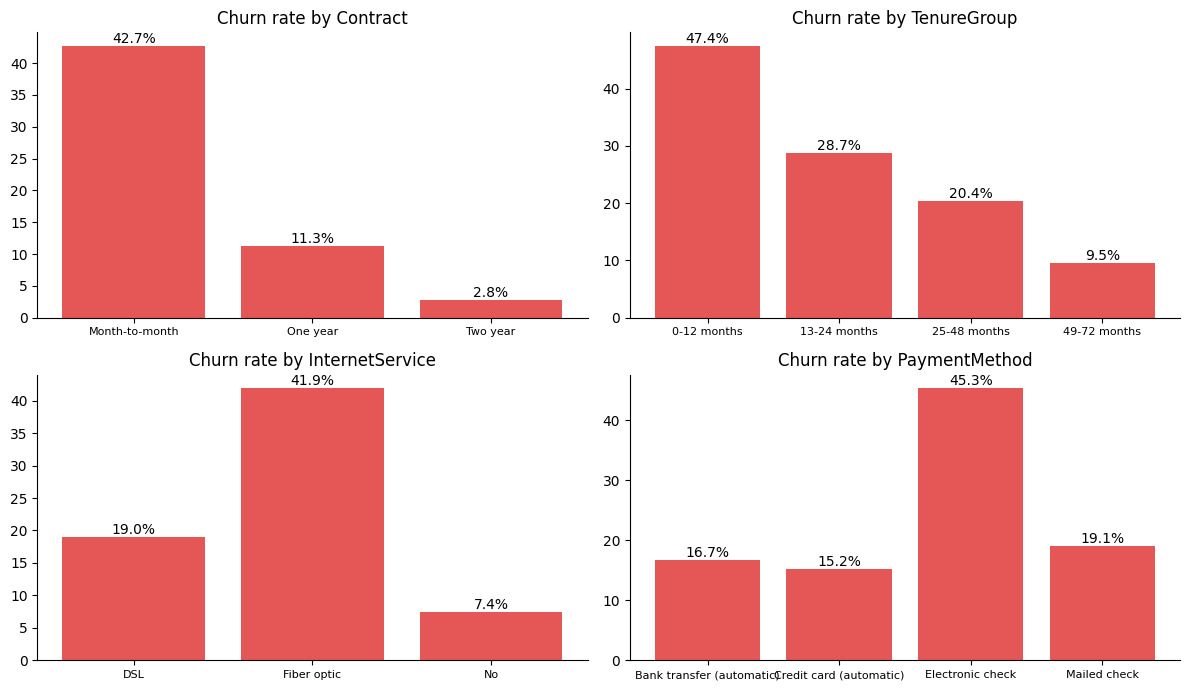

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, order) in zip(axes.ravel(), [("Contract", None), ("TenureGroup", data.TENURE_ORDER),
                                           ("InternetService", None), ("PaymentMethod", None)]):
    rate = df.groupby(col).Churn.mean().mul(100)
    if order: rate = rate.reindex(order)
    b = ax.bar(rate.index, rate.values, color=plots.CHURN); ax.bar_label(b, fmt="%.1f%%")
    ax.set_title(f"Churn rate by {col}"); ax.tick_params(axis="x", labelsize=8)
    ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Observations:** month-to-month contracts churn roughly 15x more than two-year contracts; churn falls steadily with tenure; fibre-optic and electronic-check customers churn more. These are *patterns*, not proof of cause.

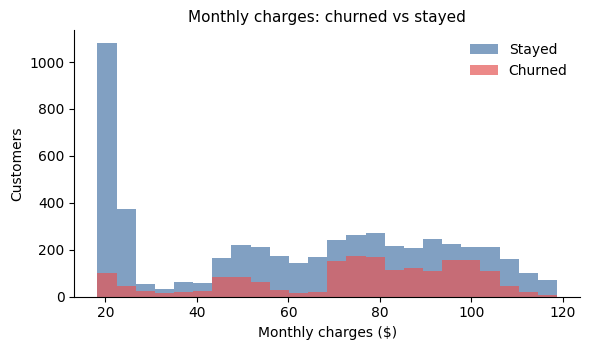

In [7]:
plots.charges_hist(df); plt.show()

## 3. Churn prediction with Logistic Regression
Pipeline = StandardScaler (numeric) + OneHotEncoder (categorical) + `LogisticRegression(class_weight='balanced')`. Bundling preprocessing into the pipeline prevents leakage from the test set.

In [8]:
X, y = df[model.FEATURES], df.Churn
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
pipe = model.build_pipeline().fit(X_tr, y_tr)
print("train:", X_tr.shape, " test:", X_te.shape, " churn share train/test:", round(y_tr.mean(),3), round(y_te.mean(),3))

train: (5634, 19)  test: (1409, 19)  churn share train/test: 0.265 0.265


## 4. Model evaluation

In [9]:
p_te = pipe.predict_proba(X_te)[:, 1]
m = model.evaluate(y_te, p_te)
pd.Series({k: round(v, 3) for k, v in m.items() if k in ["accuracy","precision","recall","f1","roc_auc","baseline_accuracy"]})

accuracy             0.740
precision            0.507
recall               0.786
f1                   0.616
roc_auc              0.842
baseline_accuracy    0.735
dtype: float64

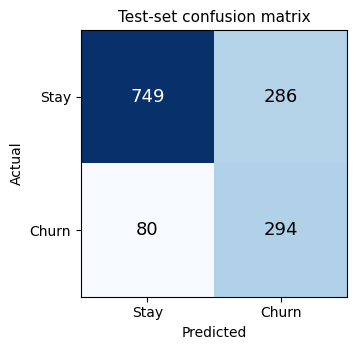

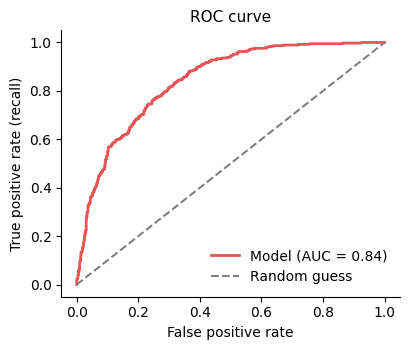

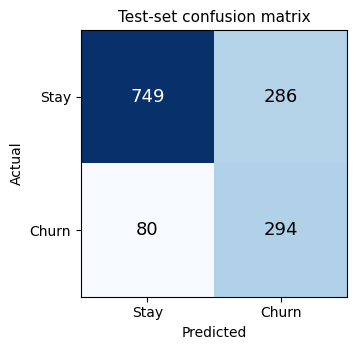

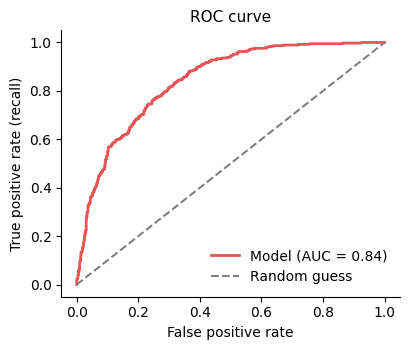

In [10]:
from IPython.display import display
display(plots.confusion_fig(m["confusion"], "Test-set confusion matrix"), plots.roc_fig(y_te, p_te, m["roc_auc"]))

### Why accuracy alone is misleading
Only ~27% of customers churn, so a model that always predicts "stays" is already ~73% accurate - yet it finds **zero** churners.

In [11]:
dummy = model.evaluate(y_te, np.zeros(len(y_te)))
pd.DataFrame({"Predict nobody churns": dummy, "Logistic Regression": m}).loc[["accuracy","precision","recall","f1"]].round(3)

,Predict nobody churns,Logistic Regression
accuracy,0.734564,0.740241
precision,0.0,0.506897
recall,0.0,0.786096
f1,0.0,0.616352


Precision = of those we flag, how many really churn. Recall = of those who churn, how many we catch. Choosing the threshold is a business decision:

In [12]:
pd.DataFrame([model.evaluate(y_te, p_te, t) for t in (0.3, 0.4, 0.5, 0.6, 0.7)])[["threshold","accuracy","precision","recall","f1"]].round(3)

,threshold,accuracy,precision,recall,f1
0,0.3,0.656,0.432,0.928,0.589
1,0.4,0.700,0.466,0.866,0.606
2,0.5,0.740,0.507,0.786,0.616
3,0.6,0.762,0.540,0.703,0.611
4,0.7,0.790,0.604,0.604,0.604


### Which factors are associated with churn?

,feature,coefficient,odds_ratio,direction
0,tenure,-1.154,0.315,lowers churn risk
1,InternetService = No,-1.133,0.322,lowers churn risk
2,InternetService = Fiber optic,1.042,2.834,raises churn risk
3,Contract = Two year,-0.755,0.470,lowers churn risk
4,Contract = Month-to-month,0.682,1.978,raises churn risk
5,TotalCharges,0.486,1.626,raises churn risk
6,MonthlyCharges,-0.366,0.694,lowers churn risk
7,PaymentMethod = Electronic check,0.259,1.296,raises churn risk
8,StreamingMovies = No,-0.244,0.784,lowers churn risk
9,OnlineSecurity = Yes,-0.241,0.786,lowers churn risk


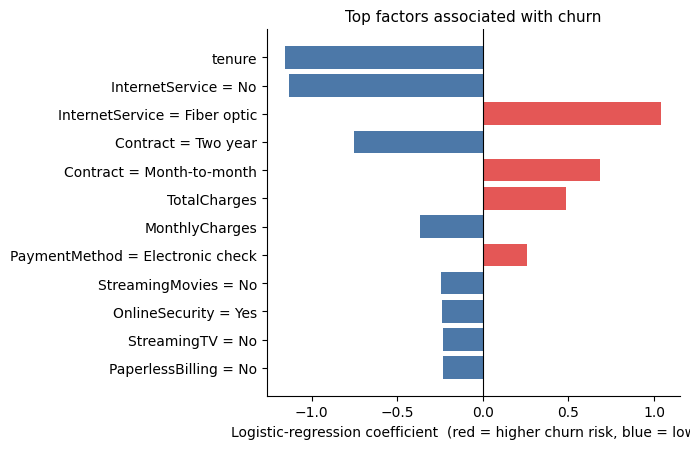

In [13]:
imp = model.feature_importance(pipe)
display(imp.head(10).round(3))
plots.importance_fig(imp); plt.show()

Positive coefficients (odds ratio > 1) go with higher churn; negative with lower. **Caution:** `TotalCharges`, `tenure` and `MonthlyCharges` are correlated, so read them together. Associations are not causes.

## 5. Risk categorisation
Customer-level scores use 5-fold out-of-fold probabilities so no customer is scored by a model that saw them in training.

In [14]:
oof = cross_val_predict(model.build_pipeline(), X, y, method="predict_proba",
                        cv=StratifiedKFold(5, shuffle=True, random_state=42))[:, 1]
scored = df.assign(churn_probability=oof.round(4), risk_band=model.risk_band(oof))
scored.groupby("risk_band").agg(customers=("Churn","size"), actual_churn_rate=("Churn","mean"),
                                avg_monthly_charge=("MonthlyCharges","mean")).reindex(model.RISK_LABELS).round(3)

,customers,actual_churn_rate,avg_monthly_charge
risk_band,,,
Low,2966,0.048,55.453
Medium,1722,0.235,63.117
High,2355,0.562,77.688


In [15]:
scored.sort_values("churn_probability", ascending=False)[["customerID","churn_probability","risk_band","Contract","tenure","MonthlyCharges","Churn"]].head(10)

,customerID,churn_probability,risk_band,Contract,tenure,MonthlyCharges,Churn
1976,9497-QCMMS,0.9424,High,Month-to-month,1,93.55,1
4800,9300-AGZNL,0.9417,High,Month-to-month,1,94.00,1
3749,4424-TKOPW,0.9412,High,Month-to-month,2,93.85,1
6368,2720-WGKHP,0.9410,High,Month-to-month,2,94.00,1
3380,5178-LMXOP,0.9367,High,Month-to-month,1,95.10,1
997,1374-DMZUI,0.9321,High,Month-to-month,4,94.30,1
301,8098-LLAZX,0.9316,High,Month-to-month,4,95.45,1
2208,7216-EWTRS,0.9314,High,Month-to-month,1,100.80,1
3159,5150-ITWWB,0.9292,High,Month-to-month,3,94.85,0
2577,4910-GMJOT,0.9283,High,Month-to-month,1,94.60,1


## 6. Going further: feature engineering & model comparison
We add five derived features (number of services, average monthly spend, current bill vs. average, auto-pay flag, new-customer flag)
and compare Logistic Regression with a tuned version, Random Forest and Gradient Boosting on identical 5-fold cross-validation folds.

In [16]:
from churn import advanced
eng = advanced.add_engineered_features(df)
eng[["customerID","NumServices","AvgMonthlySpend","BillVsAverage","IsAutoPay","IsNewCustomer","Churn"]].head()

,customerID,NumServices,AvgMonthlySpend,BillVsAverage,IsAutoPay,IsNewCustomer,Churn
0,7590-VHVEG,2,29.850000,0.000000,No,Yes,0
1,5575-GNVDE,4,55.573529,1.376471,No,No,0
2,3668-QPYBK,4,54.075000,-0.225000,No,Yes,1
3,7795-CFOCW,4,40.905556,1.394444,Yes,No,0
4,9237-HQITU,2,75.825000,-5.125000,No,Yes,1


,model,roc_auc,pr_auc,precision,recall,f1,roc_auc_std
0,Logistic Regression (baseline),0.845,0.656,0.513,0.801,0.626,0.013
1,Logistic Regression + engineered features,0.847,0.661,0.520,0.800,0.630,0.011
2,"Logistic Regression + engineered, tuned C",0.847,0.661,0.521,0.800,0.631,0.012
3,Random Forest,0.844,0.654,0.559,0.706,0.624,0.010
4,Gradient Boosting,0.844,0.656,0.517,0.796,0.627,0.009


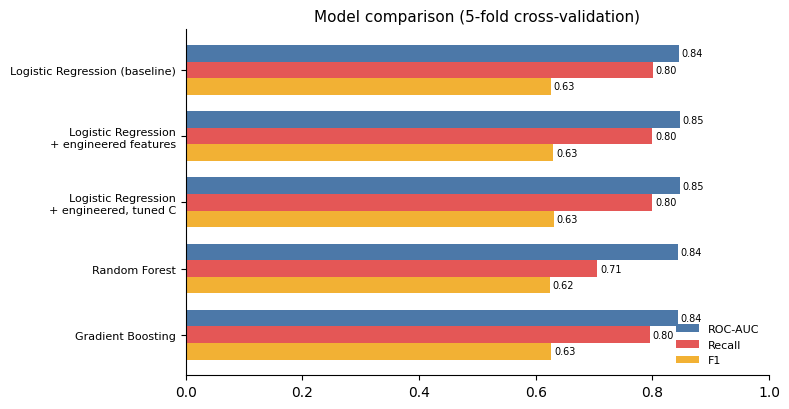

In [17]:
comp = advanced.compare_models(df)
display(comp)
plots.model_comparison_fig(comp); plt.show()

**Finding:** every model lands within ~0.003 ROC-AUC of the others. The extra complexity buys nothing here, so Logistic Regression is a justified choice - it is as accurate *and* explainable.

## 7. Business value: retention-campaign ROI
Offers cost money, so which customers should we target? Assumptions: $50 per offer, 30% of would-be churners saved, 12 months of billing retained per saved customer.

,threshold,customers_targeted,churners_reached,campaign_cost,revenue_saved,net_benefit,roi
0,0.05,5992,1852,299600.0,497811.24,198211.24,0.66
2,0.15,5001,1818,250050.0,489621.42,239571.42,0.96
4,0.25,4351,1757,217550.0,473325.48,255775.48,1.18
6,0.35,3837,1700,191850.0,460097.46,268247.46,1.40
8,0.45,3190,1563,159500.0,432265.68,272765.68,1.71
10,0.55,2654,1430,132700.0,401379.48,268679.48,2.02
12,0.65,2088,1237,104400.0,353510.28,249110.28,2.39
14,0.75,1444,970,72200.0,283531.14,211331.14,2.93
16,0.85,573,441,28650.0,131861.70,103211.70,3.60
18,0.95,0,0,0.0,0.00,0.00,0.00


Best threshold 0.45: target 3,190 customers, net benefit $272,766, ROI 1.7x


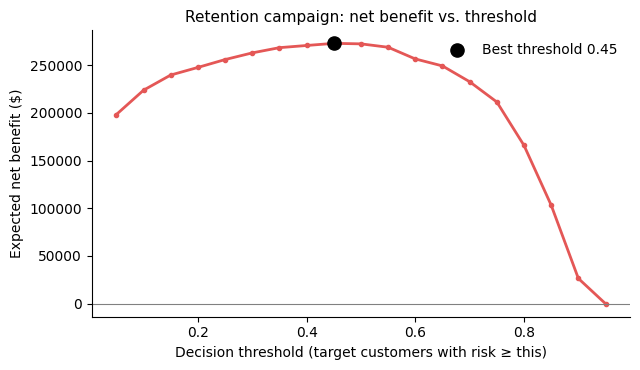

In [18]:
sweep = advanced.sweep_thresholds(y.values, oof, df.MonthlyCharges.values, offer_cost=50, success_rate=0.30, months_retained=12)
best = advanced.best_threshold(sweep)
display(sweep.round(2).iloc[::2])
print(f"Best threshold {best.threshold:.2f}: target {int(best.customers_targeted):,} customers, net benefit ${best.net_benefit:,.0f}, ROI {best.roi:.1f}x")
plots.roi_curve_fig(sweep, best); plt.show()

The most profitable threshold depends on offer cost, success rate and customer value - it moves as those assumptions change (try a cheaper offer and watch it drop), so it should not be fixed at 0.50 by default.

## 8. Takeaways
- Model catches ~79% of churners (recall) with ~51% precision on unseen data; ROC-AUC ≈ 0.84.
- Observed churn climbs from ~5% (Low) to ~56% (High), so the bands are useful for prioritising outreach.
- Biggest associated factors: short tenure, month-to-month contract, fibre-optic internet, electronic-check payment, no tech support.
- Five models perform almost identically (ROC-AUC ≈ 0.845), so simple Logistic Regression is justified.
- A business-cost threshold (not 0.50) maximises campaign profit.
- **Limitation:** these are associations in historical data - they do not prove why a particular customer leaves.